In [1]:
!pip install -q pandas numpy matplotlib

In [2]:
!pip install -q sentence-transformers

In [3]:
!pip install -q faiss-cpu

In [4]:
!pip install -q pypdf

In [5]:
!pip install -q gradio

In [6]:
print("Nutri-Intelligence environment setup completed!")

Nutri-Intelligence environment setup completed!


In [7]:

# STEP 2.1: Create Project Folder Structure

import os

BASE_DIR = "/content/Nutri_Intelligence"

folders = [
    "data/raw",
    "data/processed",
    "documents",
    "embeddings",
    "models",
    "outputs"
]

for folder in folders:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)

print("Project folders created successfully!")

for folder in folders:
    print(os.path.join(BASE_DIR, folder))


Project folders created successfully!
/content/Nutri_Intelligence/data/raw
/content/Nutri_Intelligence/data/processed
/content/Nutri_Intelligence/documents
/content/Nutri_Intelligence/embeddings
/content/Nutri_Intelligence/models
/content/Nutri_Intelligence/outputs


In [8]:

# STEP 2.2: Upload Nutrition Reports and Datasets

from google.colab import files
import os
import shutil

UPLOAD_DIR = "/content/Nutri_Intelligence/data/raw"
os.makedirs(UPLOAD_DIR, exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
    source = os.path.join("/content", filename)
    destination = os.path.join(UPLOAD_DIR, filename)

    shutil.move(source, destination)

print("\nUploaded files:")
for filename in os.listdir(UPLOAD_DIR):
    print(filename)


Saving Nutri-Intelligence Prototype Specification.docx to Nutri-Intelligence Prototype Specification (1).docx

Uploaded files:
Nutri-Intelligence Prototype Specification (1).docx


In [11]:

# Check uploaded PDF files

import os

print("Files available in Colab:")

for file in os.listdir("/content"):
    if file.lower().endswith(".pdf"):
        print(file)


Files available in Colab:


In [12]:
!pip install -q python-docx pypdf

In [13]:

# STEP 2.3: Read Teacher's Project Specification

import os
from docx import Document
from pypdf import PdfReader

file_path = None

for filename in os.listdir("/content"):
    if filename.lower().endswith((".pdf", ".docx")):
        file_path = os.path.join("/content", filename)
        break

if file_path is None:
    print("No PDF or DOCX found. Please upload your file first.")

else:
    print("Reading:", os.path.basename(file_path))

    if file_path.lower().endswith(".pdf"):
        reader = PdfReader(file_path)
        extracted_text = "\n".join(
            page.extract_text() or ""
            for page in reader.pages
        )

    else:
        doc = Document(file_path)
        extracted_text = "\n".join(
            p.text for p in doc.paragraphs
        )

    print("\nDOCUMENT CONTENT:\n")
    print(extracted_text[:5000])

    output_path = "/content/Nutri_Intelligence/data/processed/teacher_specification.txt"

    os.makedirs(os.path.dirname(output_path), exist_ok=True)

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(extracted_text)

    print("\nDocument extracted and saved successfully!")


Reading: Nutri-Intelligence Prototype Specification.docx

DOCUMENT CONTENT:

Nutri-Intelligence: Prototype Specification
Islamabad Capital Territory (ICT) and Rawalpindi pilot · Version 0.1 · 12 November 2026 · For the software engineering team
1. Purpose and scope
Nutri-Intelligence is a geospatial, LLM-assisted decision-support platform. A user selects an area on a map (district, tehsil, later union council) and asks questions in natural language. The system answers with (a) the nutrition status of that area, (b) the socio-economic, environmental and health drivers behind it, (c) ongoing programmes covering it, and (d) candidate interventions. Every number is shown with its source, year and whether it is measured or modelled.
Prototype goal (8 to 10 weeks): a working web app for ICT and Rawalpindi District with an interactive map, a chat assistant grounded only in the platform's own data, five charts per area, and a data-provenance panel. Out of scope for the prototype: live hospital

In [14]:
import pandas as pd

In [15]:
import os

In [16]:
data = [
    # Islamabad - NNS 2018
    ["Islamabad", "Stunting", 32.6, "%", "measured", "NNS", 2018],
    ["Islamabad", "Wasting", 12.1, "%", "measured", "NNS", 2018],
    ["Islamabad", "Underweight", 19.2, "%", "measured", "NNS", 2018],
    ["Islamabad", "Overweight", 5.8, "%", "measured", "NNS", 2018],
    ["Islamabad", "Early initiation of breastfeeding", 51.0, "%", "measured", "NNS", 2018],
    ["Islamabad", "Exclusive breastfeeding", 57.6, "%", "measured", "NNS", 2018],
    ["Islamabad", "Complementary feeding", 21.9, "%", "measured", "NNS", 2018],
    ["Islamabad", "Food insecure households", 33.2, "%", "measured", "NNS", 2018],
    ["Islamabad", "Coliform contaminated drinking water", 92.0, "%", "measured", "NNS", 2018],
    ["Islamabad", "Improved sanitation", 98.2, "%", "measured", "NNS", 2018],
    ["Islamabad", "Improved drinking water source", 94.9, "%", "measured", "NNS", 2018],
    ["Islamabad", "Safe disposal of child faeces", 39.4, "%", "measured", "NNS", 2018],

    # Pakistan - NNS 2018
    ["Pakistan", "Stunting", 40.2, "%", "measured", "NNS", 2018],
    ["Pakistan", "Wasting", 17.7, "%", "measured", "NNS", 2018],
    ["Pakistan", "Underweight", 28.9, "%", "measured", "NNS", 2018],
    ["Pakistan", "Overweight", 9.5, "%", "measured", "NNS", 2018],
    ["Pakistan", "Child anaemia", 53.7, "%", "measured", "NNS", 2018],
    ["Pakistan", "Women anaemia", 41.7, "%", "measured", "NNS", 2018],
    ["Pakistan", "Food insecure households", 36.9, "%", "measured", "NNS", 2018],
    ["Pakistan", "Iodized salt use", 79.6, "%", "measured", "NNS", 2018],

    # Rawalpindi - MICS 2018
    ["Rawalpindi", "Stunting", 22.2, "%", "measured", "MICS", 2018],
    ["Rawalpindi", "Underweight", 13.4, "%", "measured", "MICS", 2018],

    # Punjab - MICS 2018
    ["Punjab", "Stunting", 31.5, "%", "measured", "MICS", 2018],
    ["Punjab", "Underweight", 21.2, "%", "measured", "MICS", 2018],
    ["Punjab", "Wasting", 7.5, "%", "measured", "MICS", 2018],
]

columns = [
    "geography",
    "indicator",
    "value",
    "unit",
    "status",
    "survey",
    "year"
]

df = pd.DataFrame(data, columns=columns)

# Save dataset
output_path = "/content/Nutri_Intelligence/data/processed/nutrition_data.csv"

df.to_csv(output_path, index=False)

print("Nutrition dataset created successfully!")
print("Total records:", len(df))

display(df.head(10))


Nutrition dataset created successfully!
Total records: 25


,geography,indicator,value,unit,status,survey,year
0,Islamabad,Stunting,32.6,%,measured,NNS,2018
1,Islamabad,Wasting,12.1,%,measured,NNS,2018
2,Islamabad,Underweight,19.2,%,measured,NNS,2018
3,Islamabad,Overweight,5.8,%,measured,NNS,2018
4,Islamabad,Early initiation of breastfeeding,51.0,%,measured,NNS,2018
5,Islamabad,Exclusive breastfeeding,57.6,%,measured,NNS,2018
6,Islamabad,Complementary feeding,21.9,%,measured,NNS,2018
7,Islamabad,Food insecure households,33.2,%,measured,NNS,2018
8,Islamabad,Coliform contaminated drinking water,92.0,%,measured,NNS,2018
9,Islamabad,Improved sanitation,98.2,%,measured,NNS,2018


In [17]:

# STEP 3.2: Dataset Information

print("Dataset shape:", df.shape)

print("\nAvailable geographical areas:")
print(df["geography"].unique())

print("\nAvailable indicators:")
print(df["indicator"].unique())

print("\nEvidence status:")
print(df["status"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (25, 7)

Available geographical areas:
['Islamabad' 'Pakistan' 'Rawalpindi' 'Punjab']

Available indicators:
['Stunting' 'Wasting' 'Underweight' 'Overweight'
 'Early initiation of breastfeeding' 'Exclusive breastfeeding'
 'Complementary feeding' 'Food insecure households'
 'Coliform contaminated drinking water' 'Improved sanitation'
 'Improved drinking water source' 'Safe disposal of child faeces'
 'Child anaemia' 'Women anaemia' 'Iodized salt use']

Evidence status:
status
measured    25
Name: count, dtype: int64

Missing values:
geography    0
indicator    0
value        0
unit         0
status       0
survey       0
year         0
dtype: int64


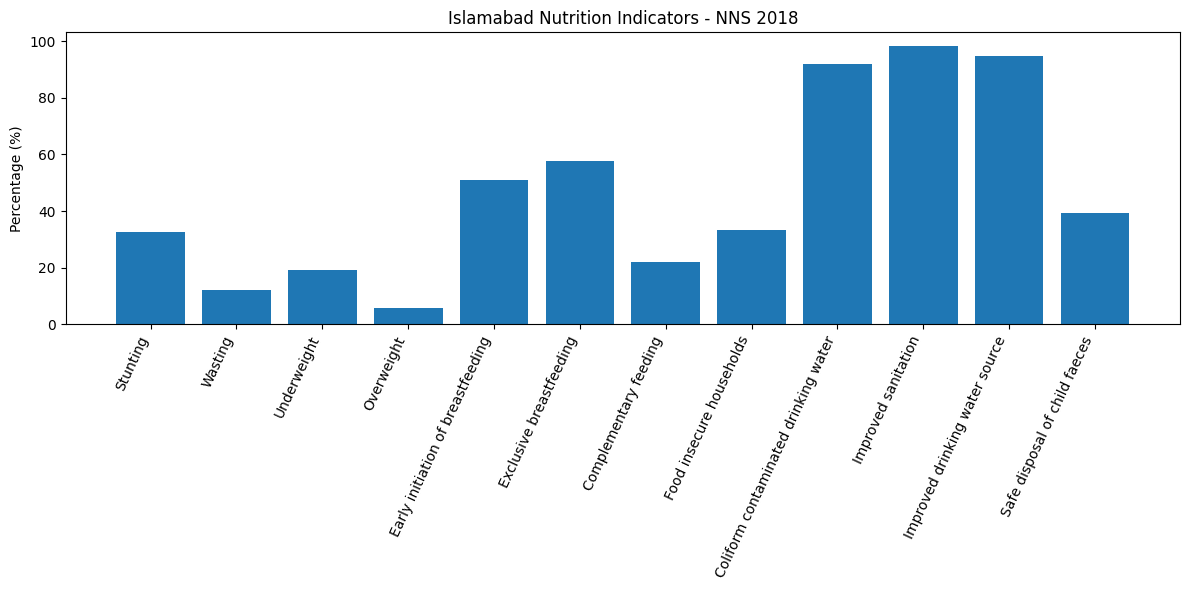

In [18]:

# STEP 3.3: Islamabad Nutrition Indicators

import matplotlib.pyplot as plt

islamabad = df[
    (df["geography"] == "Islamabad") &
    (df["survey"] == "NNS")
]

plt.figure(figsize=(12, 6))

plt.bar(
    islamabad["indicator"],
    islamabad["value"]
)

plt.title("Islamabad Nutrition Indicators - NNS 2018")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()

plt.show()


In [19]:
import pandas as pd

# Load the saved nutrition dataset
df = pd.read_csv(
    "/content/Nutri_Intelligence/data/processed/nutrition_data.csv"
)

# Display dataset structure
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

Dataset shape: (25, 7)

Column names:
['geography', 'indicator', 'value', 'unit', 'status', 'survey', 'year']

First 5 records:


,geography,indicator,value,unit,status,survey,year
0,Islamabad,Stunting,32.6,%,measured,NNS,2018
1,Islamabad,Wasting,12.1,%,measured,NNS,2018
2,Islamabad,Underweight,19.2,%,measured,NNS,2018
3,Islamabad,Overweight,5.8,%,measured,NNS,2018
4,Islamabad,Early initiation of breastfeeding,51.0,%,measured,NNS,2018



Missing values:


,0
geography,0
indicator,0
value,0
unit,0
status,0
survey,0
year,0


In [20]:
# Check how many records belong to each geography
print("Records by geography:")
display(df["geography"].value_counts())

# Check survey coverage
print("\nRecords by survey:")
display(df["survey"].value_counts())

# Check which indicators are available
print("\nAvailable indicators:")
display(df["indicator"].value_counts())

# Show all records in the dataset
display(df.sort_values(
    by=["geography", "survey", "indicator"]
).reset_index(drop=True))

Records by geography:


,count
geography,
Islamabad,12
Pakistan,8
Punjab,3
Rawalpindi,2



Records by survey:


,count
survey,
NNS,20
MICS,5



Available indicators:


,count
indicator,
Stunting,4
Underweight,4
Wasting,3
Overweight,2
Food insecure households,2
Exclusive breastfeeding,1
Early initiation of breastfeeding,1
Complementary feeding,1
Coliform contaminated drinking water,1


,geography,indicator,value,unit,status,survey,year
0,Islamabad,Coliform contaminated drinking water,92.0,%,measured,NNS,2018
1,Islamabad,Complementary feeding,21.9,%,measured,NNS,2018
2,Islamabad,Early initiation of breastfeeding,51.0,%,measured,NNS,2018
3,Islamabad,Exclusive breastfeeding,57.6,%,measured,NNS,2018
4,Islamabad,Food insecure households,33.2,%,measured,NNS,2018
5,Islamabad,Improved drinking water source,94.9,%,measured,NNS,2018
6,Islamabad,Improved sanitation,98.2,%,measured,NNS,2018
7,Islamabad,Overweight,5.8,%,measured,NNS,2018
8,Islamabad,Safe disposal of child faeces,39.4,%,measured,NNS,2018
9,Islamabad,Stunting,32.6,%,measured,NNS,2018


In [21]:

# 1. Check missing values
print("Missing Values:")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# 3. Check data types
print("\nData Types:")
print(df.dtypes)

# 4. Statistical summary
print("\nStatistical Summary:")
print(df.describe(include='all'))

# 5. Check unique values
print("\nUnique Values:")
for col in df.columns:
    print(col, ":", df[col].nunique())


Missing Values:
geography    0
indicator    0
value        0
unit         0
status       0
survey       0
year         0
dtype: int64

Duplicate Records:
0

Data Types:
geography     object
indicator     object
value        float64
unit          object
status        object
survey        object
year           int64
dtype: object

Statistical Summary:
        geography indicator     value unit    status survey    year
count          25        25  25.00000   25        25     25    25.0
unique          4        15       NaN    1         1      2     NaN
top     Islamabad  Stunting       NaN    %  measured    NNS     NaN
freq           12         4       NaN   25        25     20     NaN
mean          NaN       NaN  38.47600  NaN       NaN    NaN  2018.0
std           NaN       NaN  27.47202  NaN       NaN    NaN     0.0
min           NaN       NaN   5.80000  NaN       NaN    NaN  2018.0
25%           NaN       NaN  19.20000  NaN       NaN    NaN  2018.0
50%           NaN       NaN  32.6000

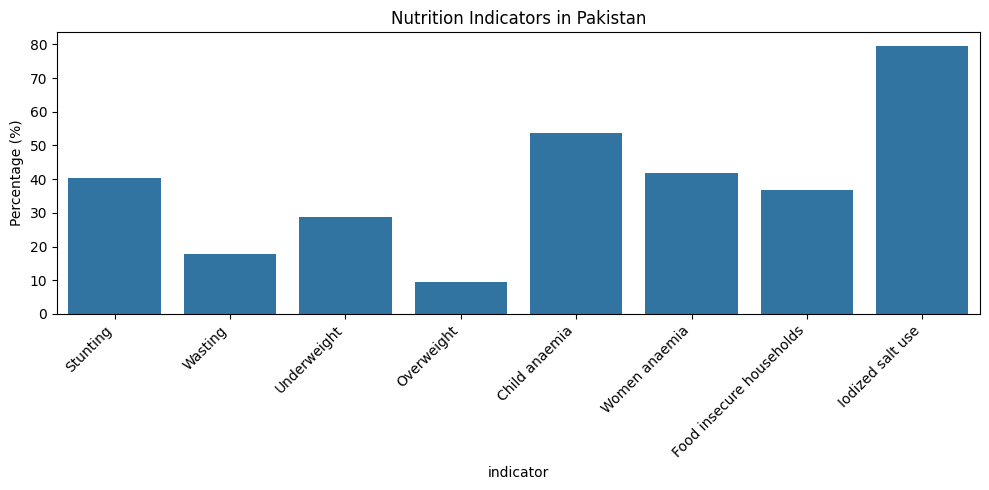

In [22]:

import matplotlib.pyplot as plt
import seaborn as sns

pakistan = df[df['geography'] == 'Pakistan']

plt.figure(figsize=(10, 5))
sns.barplot(
    data=pakistan,
    x='indicator',
    y='value'
)

plt.title('Nutrition Indicators in Pakistan')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Percentage (%)')
plt.tight_layout()
plt.show()


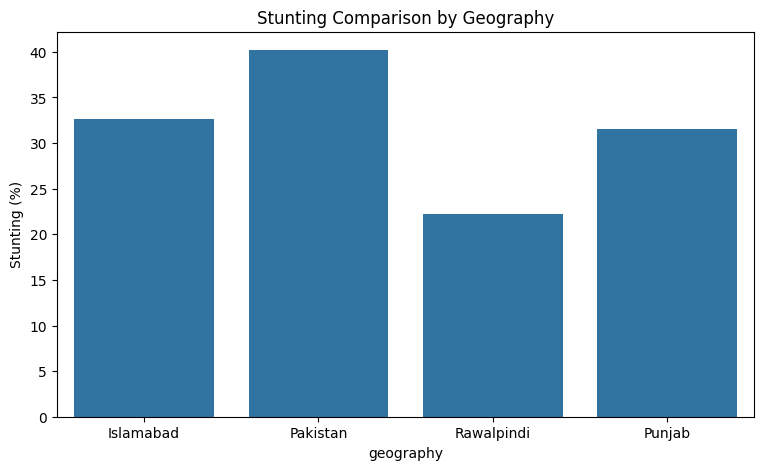

In [23]:

stunting = df[df['indicator'] == 'Stunting']

plt.figure(figsize=(9, 5))
sns.barplot(
    data=stunting,
    x='geography',
    y='value'
)

plt.title('Stunting Comparison by Geography')
plt.ylabel('Stunting (%)')
plt.show()


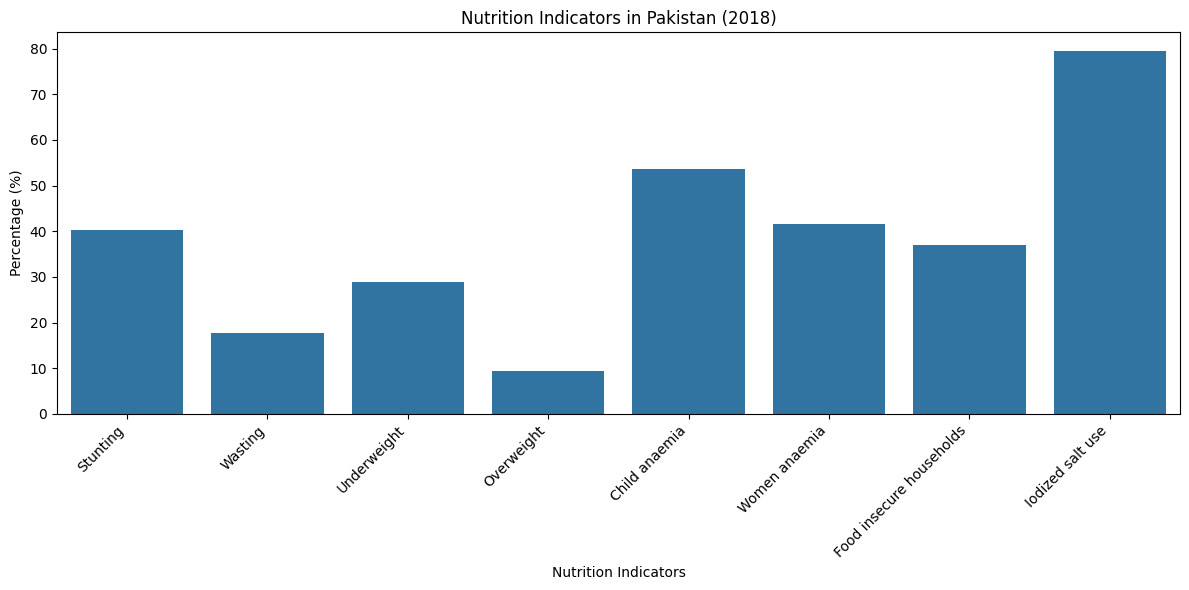

In [24]:

import matplotlib.pyplot as plt
import seaborn as sns

pakistan = df[df['geography'] == 'Pakistan']

plt.figure(figsize=(12, 6))

sns.barplot(
    data=pakistan,
    x='indicator',
    y='value'
)

plt.title('Nutrition Indicators in Pakistan (2018)')
plt.xlabel('Nutrition Indicators')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


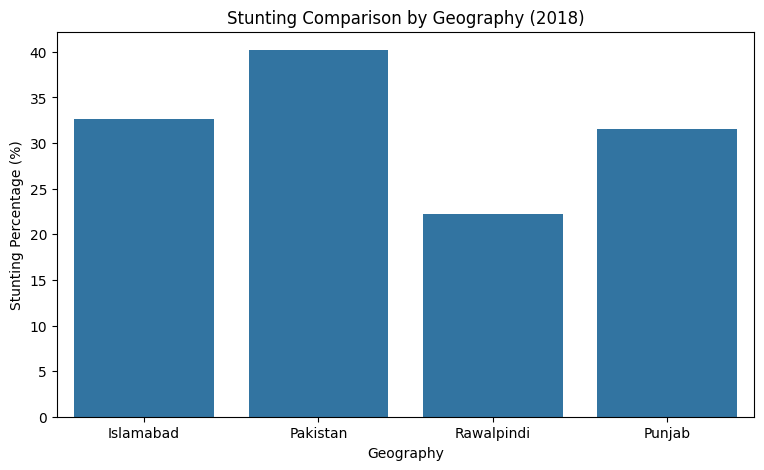

In [25]:

stunting = df[df['indicator'] == 'Stunting']

plt.figure(figsize=(9, 5))

sns.barplot(
    data=stunting,
    x='geography',
    y='value'
)

plt.title('Stunting Comparison by Geography (2018)')
plt.xlabel('Geography')
plt.ylabel('Stunting Percentage (%)')

plt.show()


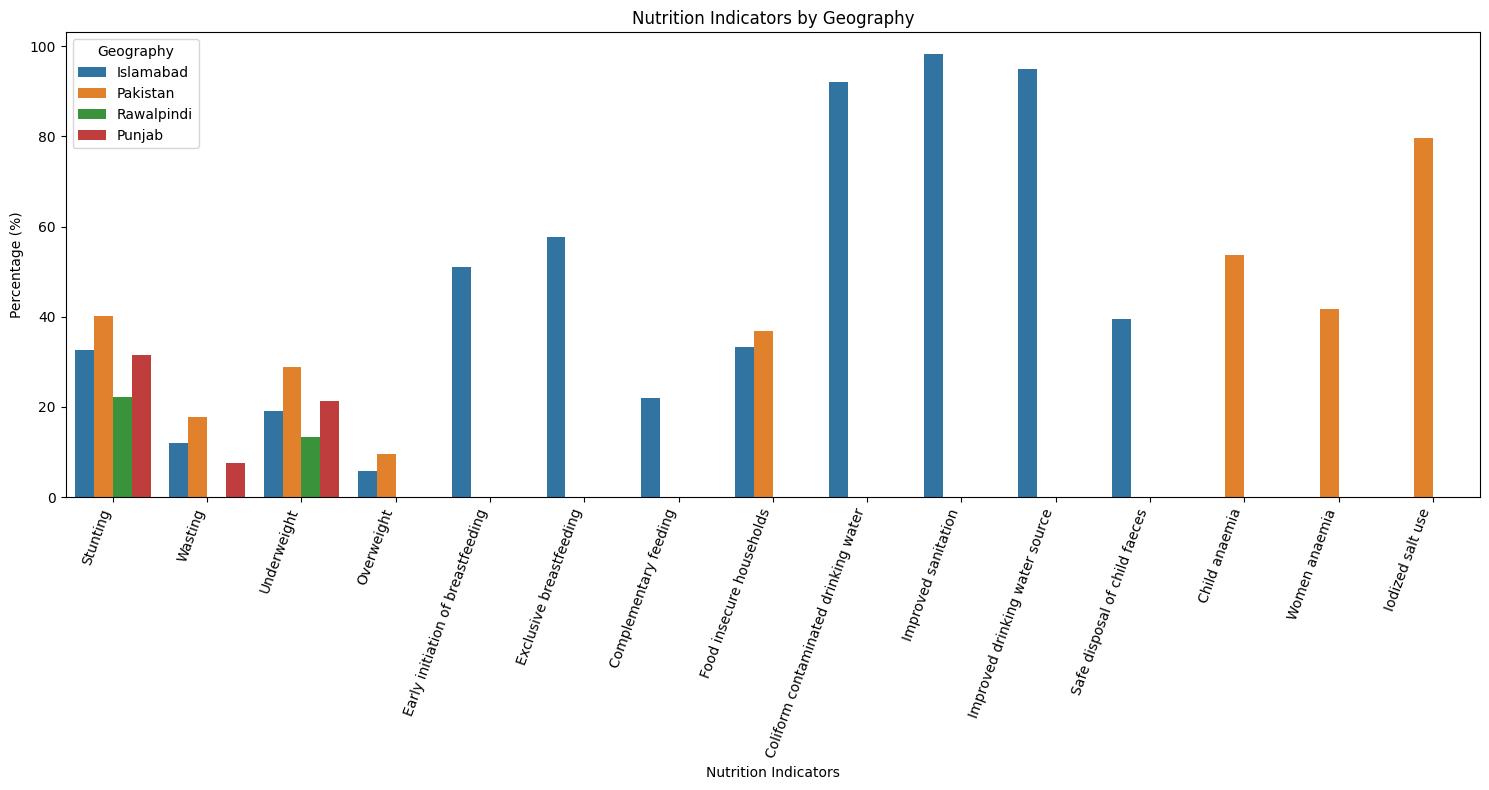

In [26]:

plt.figure(figsize=(15, 8))

sns.barplot(
    data=df,
    x='indicator',
    y='value',
    hue='geography'
)

plt.title('Nutrition Indicators by Geography')
plt.xlabel('Nutrition Indicators')
plt.ylabel('Percentage (%)')

plt.xticks(rotation=70, ha='right')
plt.legend(title='Geography')
plt.tight_layout()

plt.show()




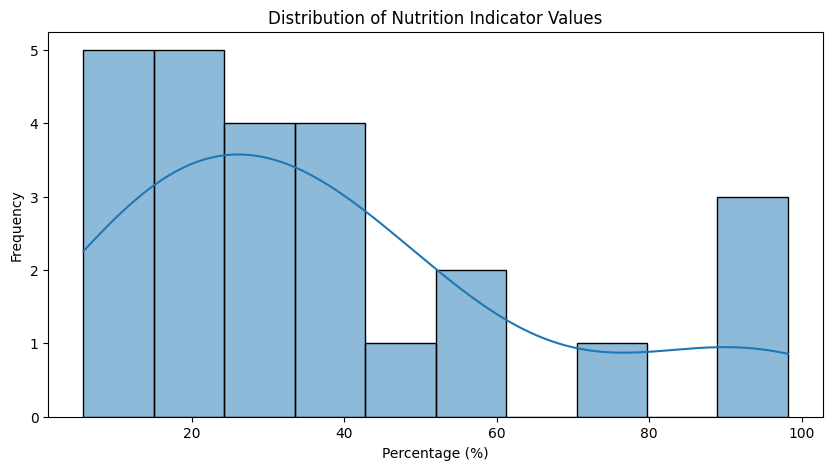

In [27]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='value',
    bins=10,
    kde=True
)

plt.title('Distribution of Nutrition Indicator Values')
plt.xlabel('Percentage (%)')
plt.ylabel('Frequency')

plt.show()


In [28]:

from sklearn.preprocessing import LabelEncoder

# Create a copy of the original dataset
ml_df = df.copy()

# Encode categorical columns
encoders = {}

categorical_columns = [
    'geography',
    'indicator',
    'status',
    'survey',
    'unit'
]

for col in categorical_columns:
    encoder = LabelEncoder()
    ml_df[col] = encoder.fit_transform(ml_df[col])
    encoders[col] = encoder

print("Encoded Dataset:")
print(ml_df.head())

print("\nFinal Data Types:")
print(ml_df.dtypes)


Encoded Dataset:
   geography  indicator  value  unit  status  survey  year
0          0         11   32.6     0       0       1  2018
1          0         13   12.1     0       0       1  2018
2          0         12   19.2     0       0       1  2018
3          0          9    5.8     0       0       1  2018
4          0          3   51.0     0       0       1  2018

Final Data Types:
geography      int64
indicator      int64
value        float64
unit           int64
status         int64
survey         int64
year           int64
dtype: object


In [29]:

# Features
X = ml_df.drop(columns=['value'])

# Target
y = ml_df['value']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())


Features Shape: (25, 6)
Target Shape: (25,)

Features:
   geography  indicator  unit  status  survey  year
0          0         11     0       0       1  2018
1          0         13     0       0       1  2018
2          0         12     0       0       1  2018
3          0          9     0       0       1  2018
4          0          3     0       0       1  2018

Target:
0    32.6
1    12.1
2    19.2
3     5.8
4    51.0
Name: value, dtype: float64


In [30]:

print("Feature Columns:")
print(X.columns.tolist())

print("\nTarget Statistics:")
print(y.describe())


Feature Columns:
['geography', 'indicator', 'unit', 'status', 'survey', 'year']

Target Statistics:
count    25.00000
mean     38.47600
std      27.47202
min       5.80000
25%      19.20000
50%      32.60000
75%      51.00000
max      98.20000
Name: value, dtype: float64


In [31]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Libraries imported successfully!")


Libraries imported successfully!


In [32]:

# Initialize model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    max_depth=5
)

# Leave-One-Out Cross Validation
loo = LeaveOneOut()

# Generate predictions
y_pred = cross_val_predict(model, X, y, cv=loo)

print("Actual Values:")
print(y.values)

print("\nPredicted Values:")
print(np.round(y_pred, 2))



Actual Values:
[32.6 12.1 19.2  5.8 51.  57.6 21.9 33.2 92.  98.2 94.9 39.4 40.2 17.7
 28.9  9.5 53.7 41.7 36.9 79.6 22.2 13.4 31.5 21.2  7.5]

Predicted Values:
[34.88 20.08 25.77 35.08 34.24 47.22 80.96 51.06 43.8  84.72 39.54 11.63
 29.83 17.57 20.83 33.8  70.94 16.84 42.3  68.62 30.24 22.31 27.32 19.71
 19.55]


In [33]:

mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print("MODEL EVALUATION")
print("----------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 2))


MODEL EVALUATION
----------------------
MAE: 17.24
MSE: 545.76
RMSE: 23.36
R2 Score: 0.25


In [34]:

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=3,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ),

    "SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel='rbf')
    )
}

loo = LeaveOneOut()
results = []

for name, model in models.items():

    predictions = cross_val_predict(
        model, X, y, cv=loo
    )

    mae = mean_absolute_error(y, predictions)
    rmse = np.sqrt(mean_squared_error(y, predictions))
    r2 = r2_score(y, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 3)
    })

results_df = pd.DataFrame(results)

print(results_df)


               Model    MAE   RMSE  R2 Score
0  Linear Regression  19.17  25.27     0.118
1      Decision Tree  17.08  22.79     0.283
2      Random Forest  17.24  23.36     0.247
3                SVR  20.74  27.44    -0.040


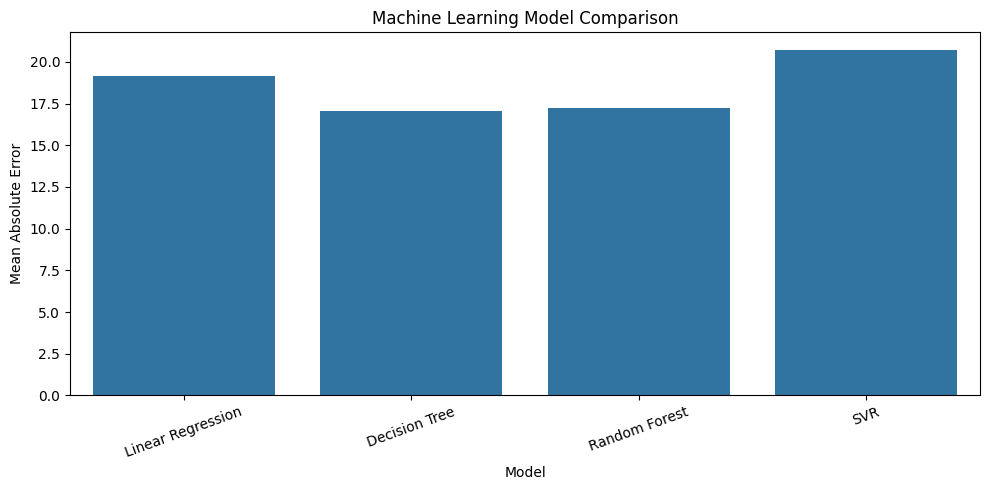

In [35]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE"
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


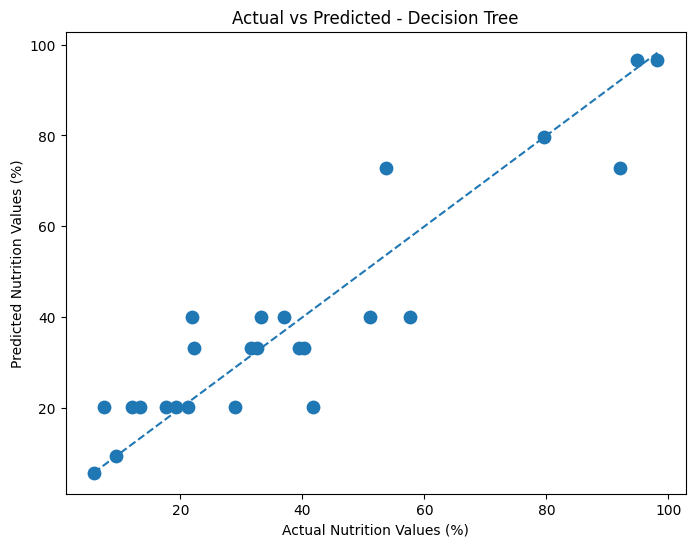

In [36]:

# Train Decision Tree using all available data
from sklearn.tree import DecisionTreeRegressor

best_model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

best_model.fit(X, y)

# Generate predictions using the fitted model
predictions = best_model.predict(X)

# Actual vs predicted visualization
plt.figure(figsize=(8, 6))

plt.scatter(y, predictions, s=80)

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    linestyle='--'
)

plt.xlabel("Actual Nutrition Values (%)")
plt.ylabel("Predicted Nutrition Values (%)")
plt.title("Actual vs Predicted - Decision Tree")

plt.show()


In [37]:

import joblib

# Save model and encoders
joblib.dump(best_model, 'nutrition_model.pkl')
joblib.dump(encoders, 'nutrition_encoders.pkl')

print("Model saved successfully!")
print("Encoders saved successfully!")


Model saved successfully!
Encoders saved successfully!


In [38]:

!pip install flask joblib
